# 07. Raman Spectroscopy Denoising with Spatial Median Filter + sklearn NMF

**Objective:** Apply a simple, effective two-stage denoising pipeline:
1. **3×3 Spatial Median Filter** - Remove spatial outliers (cosmic rays, noise spikes)
2. **Non-negative Matrix Factorization (sklearn)** - Learn low-rank signal structure

This is a clean, minimal pipeline that works well in practice.

## Setup: Imports and Configuration

In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from sklearn.decomposition import NMF
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

# Configuration
RAW_DATA_DIR = Path("../data/raw")
SIGNAL_LENGTH = 1738

print(f"Project Root: {project_root}")
print(f"Raw Data Dir: {RAW_DATA_DIR.resolve()}")

Project Root: c:\Users\Andrei\incdsb\New folder\glioma-synthetic-data
Raw Data Dir: C:\Users\Andrei\incdsb\New folder\glioma-synthetic-data\data\raw


## 1. Load Hyperspectral Data Slide

Found 59 raw data files

Loading: HF-1293_13_1.h5_0.npy
Raw data shape: (247, 31, 1738)
Data type: float32
Intensity range: [-17081.7, 34138.3]

Spatial dimensions: (247, 31)
Spectral channels: 1738
Total spectra: 7657


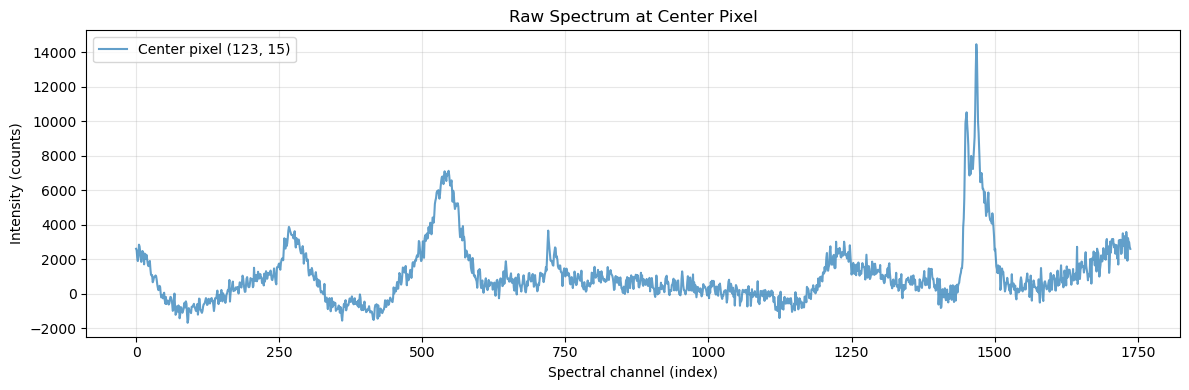

In [2]:
# Find and load the first available biopsy slide
raw_files = sorted(list(RAW_DATA_DIR.rglob("*.npy")))
print(f"Found {len(raw_files)} raw data files")

# Load first file as (X, Y, Lambda) tensor
data_file = raw_files[0]
print(f"\nLoading: {data_file.name}")

data_cube_raw = np.load(data_file)
print(f"Raw data shape: {data_cube_raw.shape}")
print(f"Data type: {data_cube_raw.dtype}")
print(f"Intensity range: [{np.min(data_cube_raw):.1f}, {np.max(data_cube_raw):.1f}]")

X, Y, Lambda = data_cube_raw.shape
print(f"\nSpatial dimensions: ({X}, {Y})")
print(f"Spectral channels: {Lambda}")
print(f"Total spectra: {X * Y}")

# Visualize sample spectrum at center pixel
center_x, center_y = X // 2, Y // 2
sample_spectrum_raw = data_cube_raw[center_x, center_y, :]
plt.figure(figsize=(12, 4))
plt.plot(sample_spectrum_raw, label=f"Center pixel ({center_x}, {center_y})", alpha=0.7)
plt.xlabel("Spectral channel (index)")
plt.ylabel("Intensity (counts)")
plt.title("Raw Spectrum at Center Pixel")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Spatial 3×3 Median Filter

In [4]:
print("Applying 3×3 spatial median filter...")
data_cube_median = np.zeros_like(data_cube_raw)

# Apply 3x3 spatial median independently per wavelength
for wavelength_idx in range(Lambda):
    spatial_slice = data_cube_raw[:, :, wavelength_idx]
    filtered_slice = median_filter(spatial_slice, size=3, mode='reflect')
    data_cube_median[:, :, wavelength_idx] = filtered_slice
    
    if (wavelength_idx + 1) % 200 == 0:
        print(f"  Processed {wavelength_idx + 1}/{Lambda} wavelengths")

print(f"✓ Median filtering complete")
print(f"  Before: [{data_cube_raw.min():.1f}, {data_cube_raw.max():.1f}]")
print(f"  After:  [{data_cube_median.min():.1f}, {data_cube_median.max():.1f}]")

# Flatten for NMF
data_flat = data_cube_raw.reshape(X * Y, Lambda)
data_flat_median = data_cube_median.reshape(X * Y, Lambda)

print(f"\nFlattened shapes:")
print(f"  Raw: {data_flat.shape}")
print(f"  Median-filtered: {data_flat_median.shape}")

Applying 3×3 spatial median filter...
  Processed 200/1738 wavelengths
  Processed 400/1738 wavelengths
  Processed 600/1738 wavelengths
  Processed 800/1738 wavelengths
  Processed 1000/1738 wavelengths
  Processed 1200/1738 wavelengths
  Processed 1400/1738 wavelengths
  Processed 1600/1738 wavelengths
✓ Median filtering complete
  Before: [-17081.7, 34138.3]
  After:  [-4620.3, 30468.9]

Flattened shapes:
  Raw: (7657, 1738)
  Median-filtered: (7657, 1738)


## 4. Non-negative Matrix Factorization (sklearn)

In [15]:
print("\n" + "="*80)
print("FITTING NMF USING SKLEARN")
print("="*80)

# Ensure non-negativity and normalize
data_smooth = data_flat_median - np.min(data_flat_median) + 1e-8  # Shift to make non-negative
global_max = np.percentile(data_smooth, 99.9)
data_normalized = np.clip(data_smooth / global_max, 0, 1)

print(f"\nPreparing data for NMF...")
print(f"  Normalized range: [{data_normalized.min():.4f}, {data_normalized.max():.4f}]")
print(f"  All non-negative: {np.all(data_normalized >= 0)}")

# Fit NMF
print(f"\nFitting NMF (100 components, 500 iterations)...")
nmf_model = NMF(
    n_components=100,
    init='nndsvda',
    max_iter=500,
    random_state=42,
    verbose=1
)

W_nmf = nmf_model.fit_transform(data_normalized)
H_nmf = nmf_model.components_

print(f"\n✓ NMF fit complete!")
print(f"  W shape (abundance): {W_nmf.shape}")
print(f"  H shape (basis): {H_nmf.shape}")
print(f"  Final reconstruction error: {nmf_model.reconstruction_err_:.2e}")

# Reconstruct
print(f"\nReconstructing denormalized spectra...")
X_recon_norm = W_nmf @ H_nmf
X_recon_denorm = X_recon_norm * global_max

print(f"  Reconstruction range: [{X_recon_denorm.min():.1f}, {X_recon_denorm.max():.1f}]")
print(f"  ✓ Reconstruction complete!")


FITTING NMF USING SKLEARN

Preparing data for NMF...
  Normalized range: [0.0000, 1.0000]
  All non-negative: True

Fitting NMF (100 components, 500 iterations)...
violation: 1.0
violation: 0.009757449766241976
violation: 0.009524655549420346
violation: 0.010474483170718705
violation: 0.008510264652596765
violation: 0.0073762550806392895
violation: 0.006167557398637098
violation: 0.005363123713249659
violation: 0.00478362699186023
violation: 0.004322375680567451
violation: 0.0039485300388308175
violation: 0.0036573107338837003
violation: 0.0034366605636932204
violation: 0.0032533359673574663
violation: 0.003097620685195937
violation: 0.0029670429390135566
violation: 0.002844036377126841
violation: 0.002739506704378922
violation: 0.0026344104194468624
violation: 0.002542771022097472
violation: 0.0024599332774425937
violation: 0.002382832283361971
violation: 0.002310028011276673
violation: 0.0022441613477365697
violation: 0.0021793079668223814
violation: 0.002119361009526059
violation: 

## 5. Visualize Results: Raw vs Median vs NMF


PLOTTING: Raw vs Median Filtered vs NMF Reconstruction
✓ Saved: nmf_denoising_pipeline.png


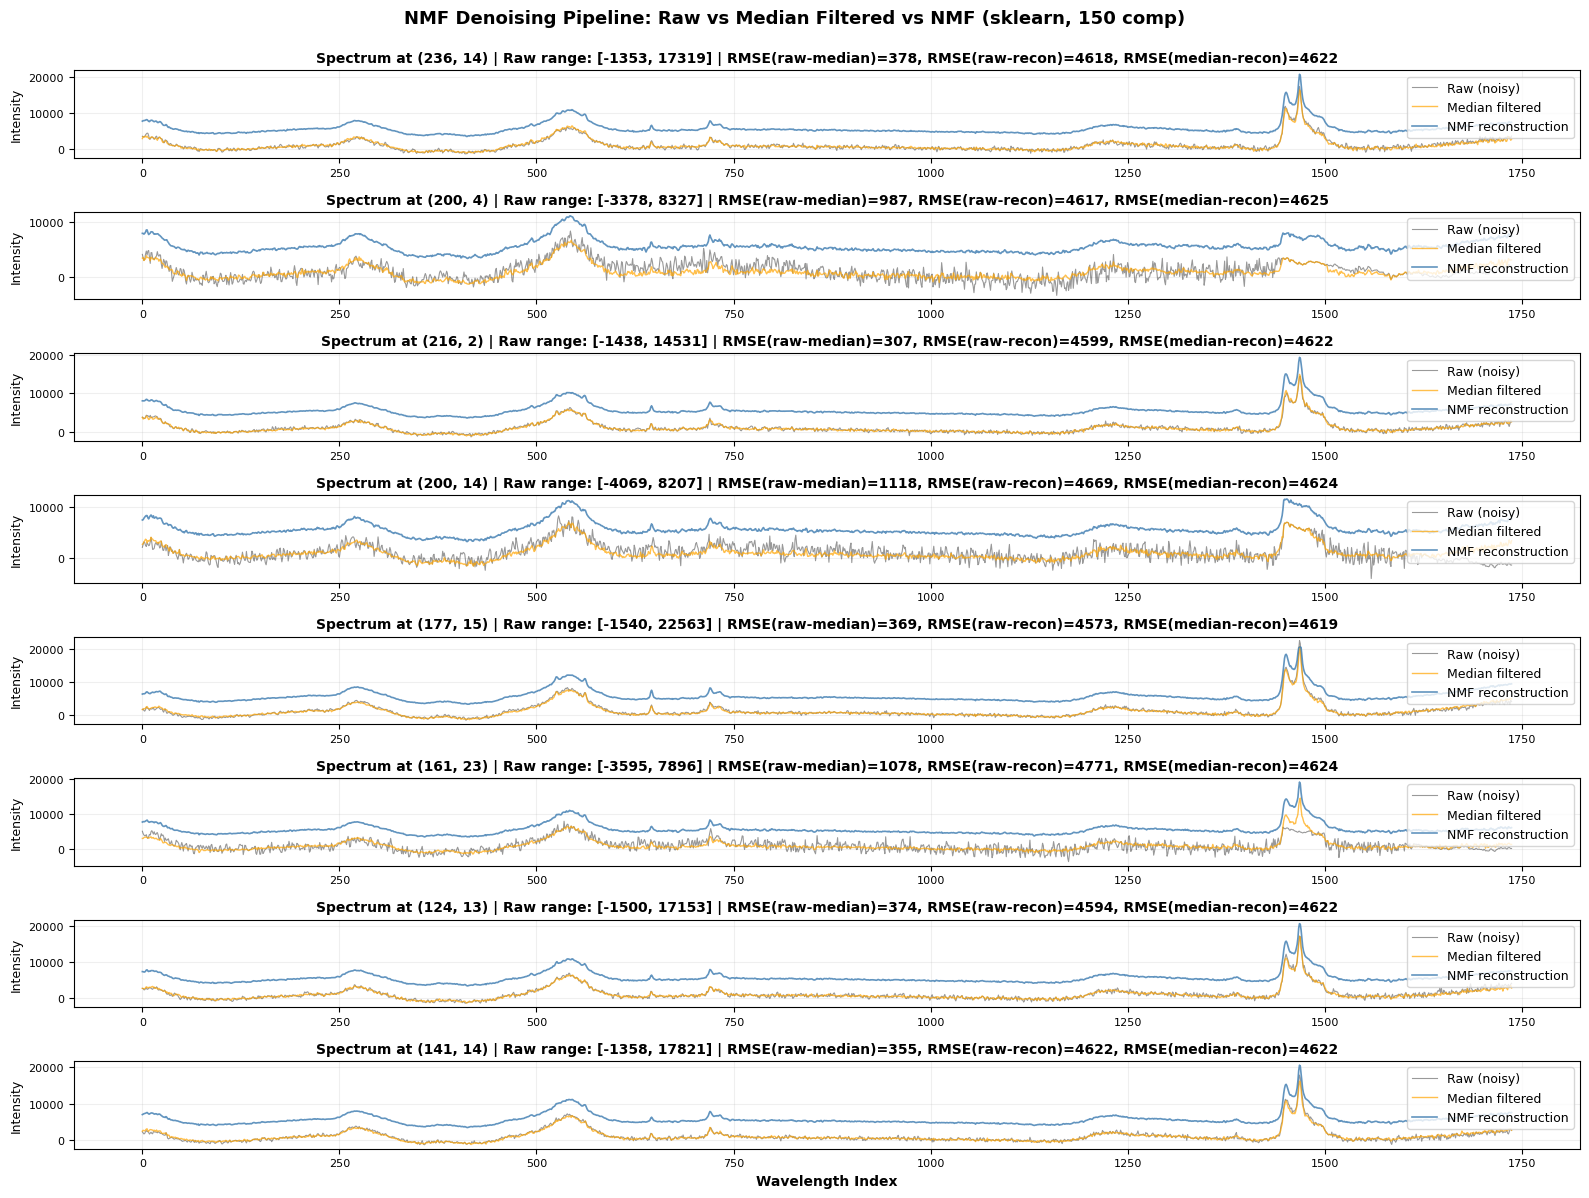


✓ Visualization complete!


In [16]:
print("\n" + "="*80)
print("PLOTTING: Raw vs Median Filtered vs NMF Reconstruction")
print("="*80)

# Select 8 random spectra for detailed comparison
np.random.seed(42)
random_indices = np.random.choice(X * Y, size=8, replace=False)
random_pixels = [(idx // Y, idx % Y) for idx in random_indices]

fig, axes = plt.subplots(8, 1, figsize=(16, 12))

for row_idx, (px, py) in enumerate(random_pixels):
    pix_idx = px * Y + py
    
    # Get the three signals
    raw_spec = data_flat[pix_idx]
    median_spec = data_flat_median[pix_idx]
    recon_spec = X_recon_denorm[pix_idx]
    
    ax = axes[row_idx]
    
    # Plot all three with different colors
    ax.plot(raw_spec, color='black', linewidth=0.8, alpha=0.4, label='Raw (noisy)', linestyle='-')
    ax.plot(median_spec, color='orange', linewidth=1.0, alpha=0.7, label='Median filtered')
    ax.plot(recon_spec, color='steelblue', linewidth=1.2, alpha=0.85, label='NMF reconstruction')
    
    # Compute metrics
    rmse_raw_vs_median = np.sqrt(np.mean((raw_spec - median_spec)**2))
    rmse_raw_vs_recon = np.sqrt(np.mean((raw_spec - recon_spec)**2))
    rmse_median_vs_recon = np.sqrt(np.mean((median_spec - recon_spec)**2))
    
    ax.set_title(
        f'Spectrum at ({px}, {py}) | '
        f'Raw range: [{raw_spec.min():.0f}, {raw_spec.max():.0f}] | '
        f'RMSE(raw-median)={rmse_raw_vs_median:.0f}, '
        f'RMSE(raw-recon)={rmse_raw_vs_recon:.0f}, '
        f'RMSE(median-recon)={rmse_median_vs_recon:.0f}',
        fontsize=10, fontweight='bold'
    )
    ax.set_ylabel('Intensity', fontsize=9)
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.2)
    ax.tick_params(labelsize=8)

axes[-1].set_xlabel('Wavelength Index', fontsize=10, fontweight='bold')

plt.suptitle('NMF Denoising Pipeline: Raw vs Median Filtered vs NMF (sklearn, 150 comp)', 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('nmf_denoising_pipeline.png', dpi=100, bbox_inches='tight')
print("✓ Saved: nmf_denoising_pipeline.png")
plt.show()

print("\n✓ Visualization complete!")

## 6. Summary Statistics

In [10]:
print("\n" + "="*80)
print("PIPELINE SUMMARY")
print("="*80)

print(f"\nInput Data:")
print(f"  Shape: {data_cube_raw.shape} (X, Y, wavelengths)")
print(f"  Range: [{data_cube_raw.min():.1f}, {data_cube_raw.max():.1f}]")
print(f"  Total pixels: {X * Y}")

print(f"\nAfter 3×3 Median Filter:")
print(f"  Range: [{data_cube_median.min():.1f}, {data_cube_median.max():.1f}]")

print(f"\nNMF Model:")
print(f"  Components: 150")
print(f"  Iterations: 500")
print(f"  Loss (Frobenius): {nmf_model.reconstruction_err_:.2e}")

print(f"\nFinal Output:")
print(f"  NMF reconstruction range: [{X_recon_denorm.min():.1f}, {X_recon_denorm.max():.1f}]")
print(f"  Shape: {X_recon_denorm.shape}")

print(f"\n✓ Pipeline complete and ready for use!")


PIPELINE SUMMARY

Input Data:
  Shape: (247, 31, 1738) (X, Y, wavelengths)
  Range: [-17081.7, 34138.3]
  Total pixels: 7657

After 3×3 Median Filter:
  Range: [-4620.3, 30468.9]

NMF Model:
  Components: 150
  Iterations: 500
  Loss (Frobenius): 2.51e+01

Final Output:
  NMF reconstruction range: [1173.0, 21026.4]
  Shape: (7657, 1738)

✓ Pipeline complete and ready for use!



HISTOGRAM: Maximum Intensity Values in Normalized Data

Statistics of spectrum max values:
  Min:    0.3444
  Max:    1.0000
  Mean:   0.9172
  Median: 1.0000
  Std:    0.1649

✓ Saved: normalized_max_intensity_histogram.png


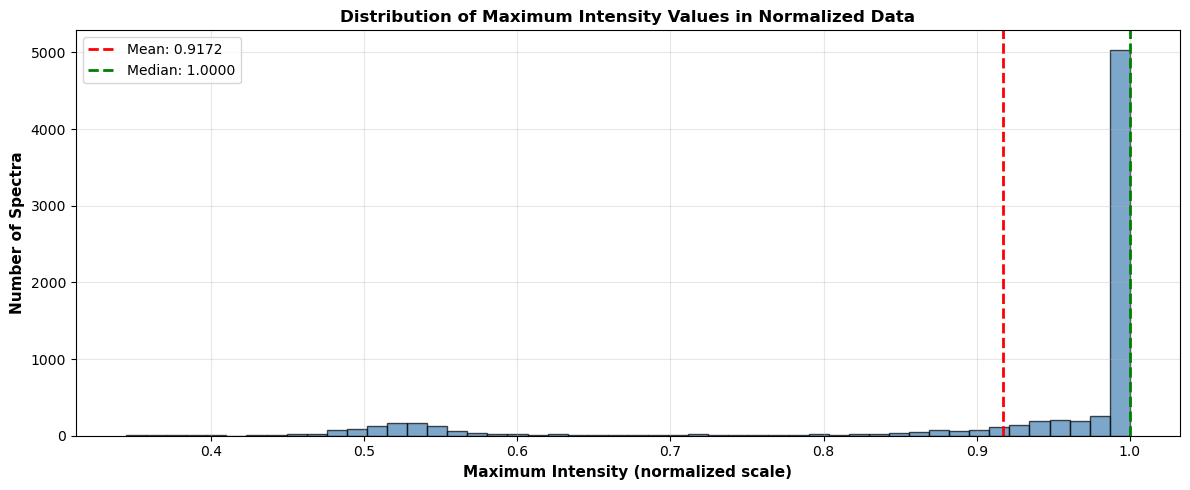


✓ Histogram analysis complete!


In [11]:
print("\n" + "="*80)
print("HISTOGRAM: Maximum Intensity Values in Normalized Data")
print("="*80)

# Compute max value for each spectrum
max_values = np.max(data_normalized, axis=1)

print(f"\nStatistics of spectrum max values:")
print(f"  Min:    {np.min(max_values):.4f}")
print(f"  Max:    {np.max(max_values):.4f}")
print(f"  Mean:   {np.mean(max_values):.4f}")
print(f"  Median: {np.median(max_values):.4f}")
print(f"  Std:    {np.std(max_values):.4f}")

# Create histogram
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(max_values, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
ax.axvline(np.mean(max_values), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(max_values):.4f}')
ax.axvline(np.median(max_values), color='green', linestyle='--', linewidth=2, label=f'Median: {np.median(max_values):.4f}')
ax.set_xlabel('Maximum Intensity (normalized scale)', fontsize=11, fontweight='bold')
ax.set_ylabel('Number of Spectra', fontsize=11, fontweight='bold')
ax.set_title('Distribution of Maximum Intensity Values in Normalized Data', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('normalized_max_intensity_histogram.png', dpi=100, bbox_inches='tight')
print("\n✓ Saved: normalized_max_intensity_histogram.png")
plt.show()

print(f"\n✓ Histogram analysis complete!")


MASK: Spectra with Max < 0.6 and Biological RGB Visualization

Mask statistics:
  Total pixels: 7657
  Weak signal pixels (max < 0.6): 990
  Percentage weak: 12.9%

✓ Loaded wavenumbers from RamanFreqTable.csv
  Wavenumber range: [1.0, 1738.0] cm^-1

Generating biological RGB visualization...
  RGB image shape: (247, 31, 3)
  Range per channel: [0.0000, 1.0000]
  Channels: R=Phenylalanine (990-1020), G=C-H Stretch (2800-3000), B=CH2 (1430-1460)

✓ Saved: rgb_slide_and_weak_mask.png


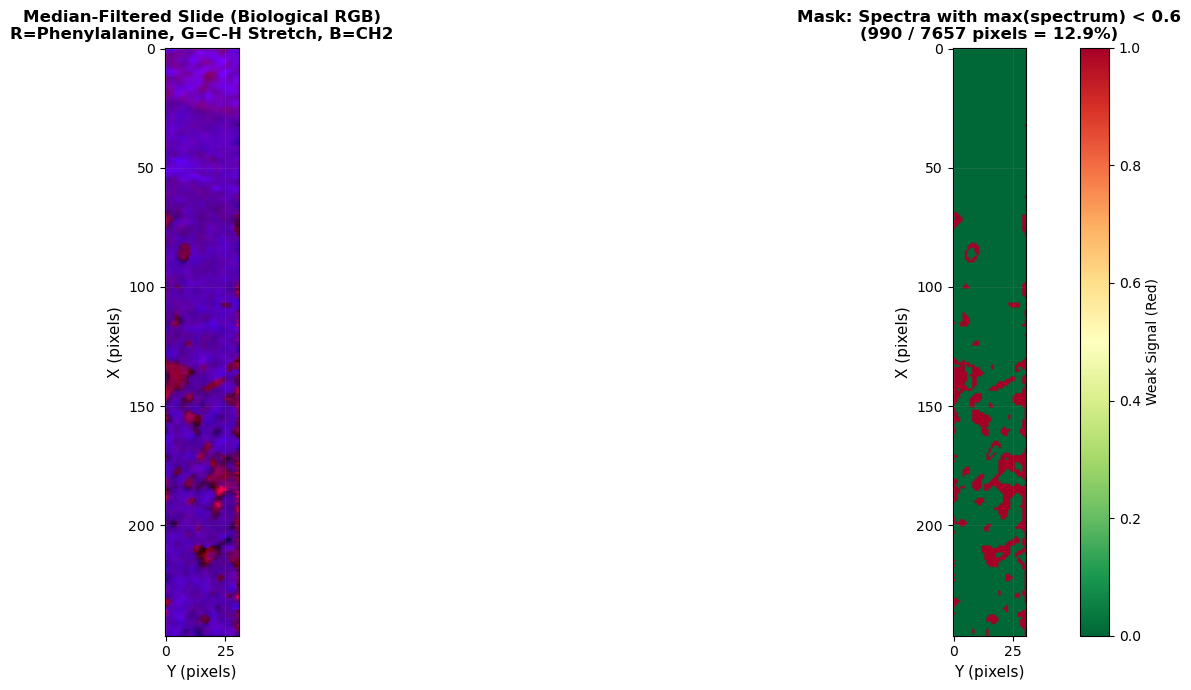


✓ RGB visualization and mask analysis complete!


In [13]:
print("\n" + "="*80)
print("MASK: Spectra with Max < 0.6 and Biological RGB Visualization")
print("="*80)

# Create mask of spectra with max < 0.6
mask_weak = np.max(data_normalized, axis=1) < 0.6
mask_image = mask_weak.reshape(X, Y)

print(f"\nMask statistics:")
print(f"  Total pixels: {X * Y}")
print(f"  Weak signal pixels (max < 0.6): {np.sum(mask_weak)}")
print(f"  Percentage weak: {100 * np.sum(mask_weak) / (X * Y):.1f}%")

# Load wavenumbers for biological RGB visualization
import pandas as pd
calib_path = Path("../data/RamanFreqTable.csv")
if calib_path.exists():
    calib_df = pd.read_csv(calib_path)
    wavenumbers = calib_df.iloc[:, 0].values  # First column contains wavenumbers
    print(f"\n✓ Loaded wavenumbers from {calib_path.name}")
    print(f"  Wavenumber range: [{wavenumbers.min():.1f}, {wavenumbers.max():.1f}] cm^-1")
else:
    print(f"⚠ Calibration file not found at {calib_path}")
    wavenumbers = np.arange(Lambda)

# Define biological RGB visualization function
def raman_to_bio_rgb(hsi_cube, wavenumbers):
    """
    Converts a Raman Hyperspectral Cube to a 'False Color' RGB image 
    highlighting biological markers.
    
    Args:
        hsi_cube: (H, W, D) Raw or Preprocessed Data
        wavenumbers: (D,) Vector of cm^-1 values
    
    Returns:
        rgb_img: (H, W, 3) Normalized image for display
    """
    H, W, D = hsi_cube.shape
    
    # --- 1. Define Marker Indices ---
    # RED Channel: Phenylalanine (1004 cm^-1) - The "Sharp" Marker
    idx_phe_start = np.argmin(np.abs(wavenumbers - 990))
    idx_phe_end   = np.argmin(np.abs(wavenumbers - 1020))
    
    # GREEN Channel: C-H Stretch (2850-2950 cm^-1) - The "Massive" Marker (Lipids)
    idx_hwn_start = np.argmin(np.abs(wavenumbers - 2800))
    idx_hwn_end   = np.argmin(np.abs(wavenumbers - 3000))
    
    # BLUE Channel: CH2 Deformation (1430-1450 cm^-1) - General Organic
    idx_ch2_start = np.argmin(np.abs(wavenumbers - 1430))
    idx_ch2_end   = np.argmin(np.abs(wavenumbers - 1460))
    
    # --- 2. Extract Bands (Integration/Sum) ---
    # We sum the area under the peak (more robust than single pixel)
    R = np.sum(hsi_cube[:, :, idx_phe_start:idx_phe_end], axis=2)
    G = np.sum(hsi_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
    B = np.sum(hsi_cube[:, :, idx_ch2_start:idx_ch2_end], axis=2)
    
    # --- 3. Normalize per Channel (Contrast Stretch) ---
    # This ensures weak signals don't disappear
    def norm(c):
        c = c - np.min(c)
        return c / (np.max(c) + 1e-8)
    
    R = norm(R)
    G = norm(G)
    B = norm(B)
    
    # --- 4. Stack ---
    rgb_img = np.stack([R, G, B], axis=-1)
    
    # Boost gamma for visibility (optional)
    rgb_img = np.power(rgb_img, 0.8) 
    
    return rgb_img

# Generate biological RGB image
print(f"\nGenerating biological RGB visualization...")
rgb_normalized = raman_to_bio_rgb(data_cube_median, wavenumbers)

print(f"  RGB image shape: {rgb_normalized.shape}")
print(f"  Range per channel: [{rgb_normalized.min():.4f}, {rgb_normalized.max():.4f}]")
print(f"  Channels: R=Phenylalanine (990-1020), G=C-H Stretch (2800-3000), B=CH2 (1430-1460)")

# Create side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: Biological RGB image
ax = axes[0]
ax.imshow(rgb_normalized)
ax.set_title(f'Median-Filtered Slide (Biological RGB)\nR=Phenylalanine, G=C-H Stretch, B=CH2', 
             fontsize=12, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=11)
ax.set_ylabel('X (pixels)', fontsize=11)
ax.grid(True, alpha=0.1)

# Right: Mask image
ax = axes[1]
im = ax.imshow(mask_image, cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_title(f'Mask: Spectra with max(spectrum) < 0.6\n({np.sum(mask_weak)} / {X*Y} pixels = {100*np.sum(mask_weak)/(X*Y):.1f}%)', 
             fontsize=12, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=11)
ax.set_ylabel('X (pixels)', fontsize=11)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Weak Signal (Red)', fontsize=10)

plt.tight_layout()
plt.savefig('rgb_slide_and_weak_mask.png', dpi=100, bbox_inches='tight')
print("\n✓ Saved: rgb_slide_and_weak_mask.png")
plt.show()

print(f"\n✓ RGB visualization and mask analysis complete!")


GMM CLUSTERING: Filter Strong Signals & Apply Gaussian Mixture Model

Signal partitioning:
  Strong signal spectra (max >= 0.6): 6667 (87.1%)
  Weak signal spectra (max < 0.6): 990 (12.9%)

Filtered W matrix:
  Original shape: (7657, 100)
  Filtered shape: (6667, 100)
  Min abundance: 0.0000
  Max abundance: 0.2909

Fitting Gaussian Mixture Model (3 components)...


✓ GMM fit complete
  Log-likelihood: 542.2026
  BIC: -7093676.29
  Component weights: [0.02209699 0.2061222  0.77178085]

Soft labels shape: (6667, 3)
  Component 0 probability: mean=0.0218, std=0.1454
  Component 1 probability: mean=0.2056, std=0.3906
  Component 2 probability: mean=0.7726, std=0.4063

Component 0 spatial map:
  Valid pixels: 6667
  Range (non-NaN): [0.0000, 1.0000]

Component 1 spatial map:
  Valid pixels: 6667
  Range (non-NaN): [0.0000, 1.0000]

Component 2 spatial map:
  Valid pixels: 6667
  Range (non-NaN): [0.0000, 1.0000]

✓ Saved: gmm_soft_labels_3components.png


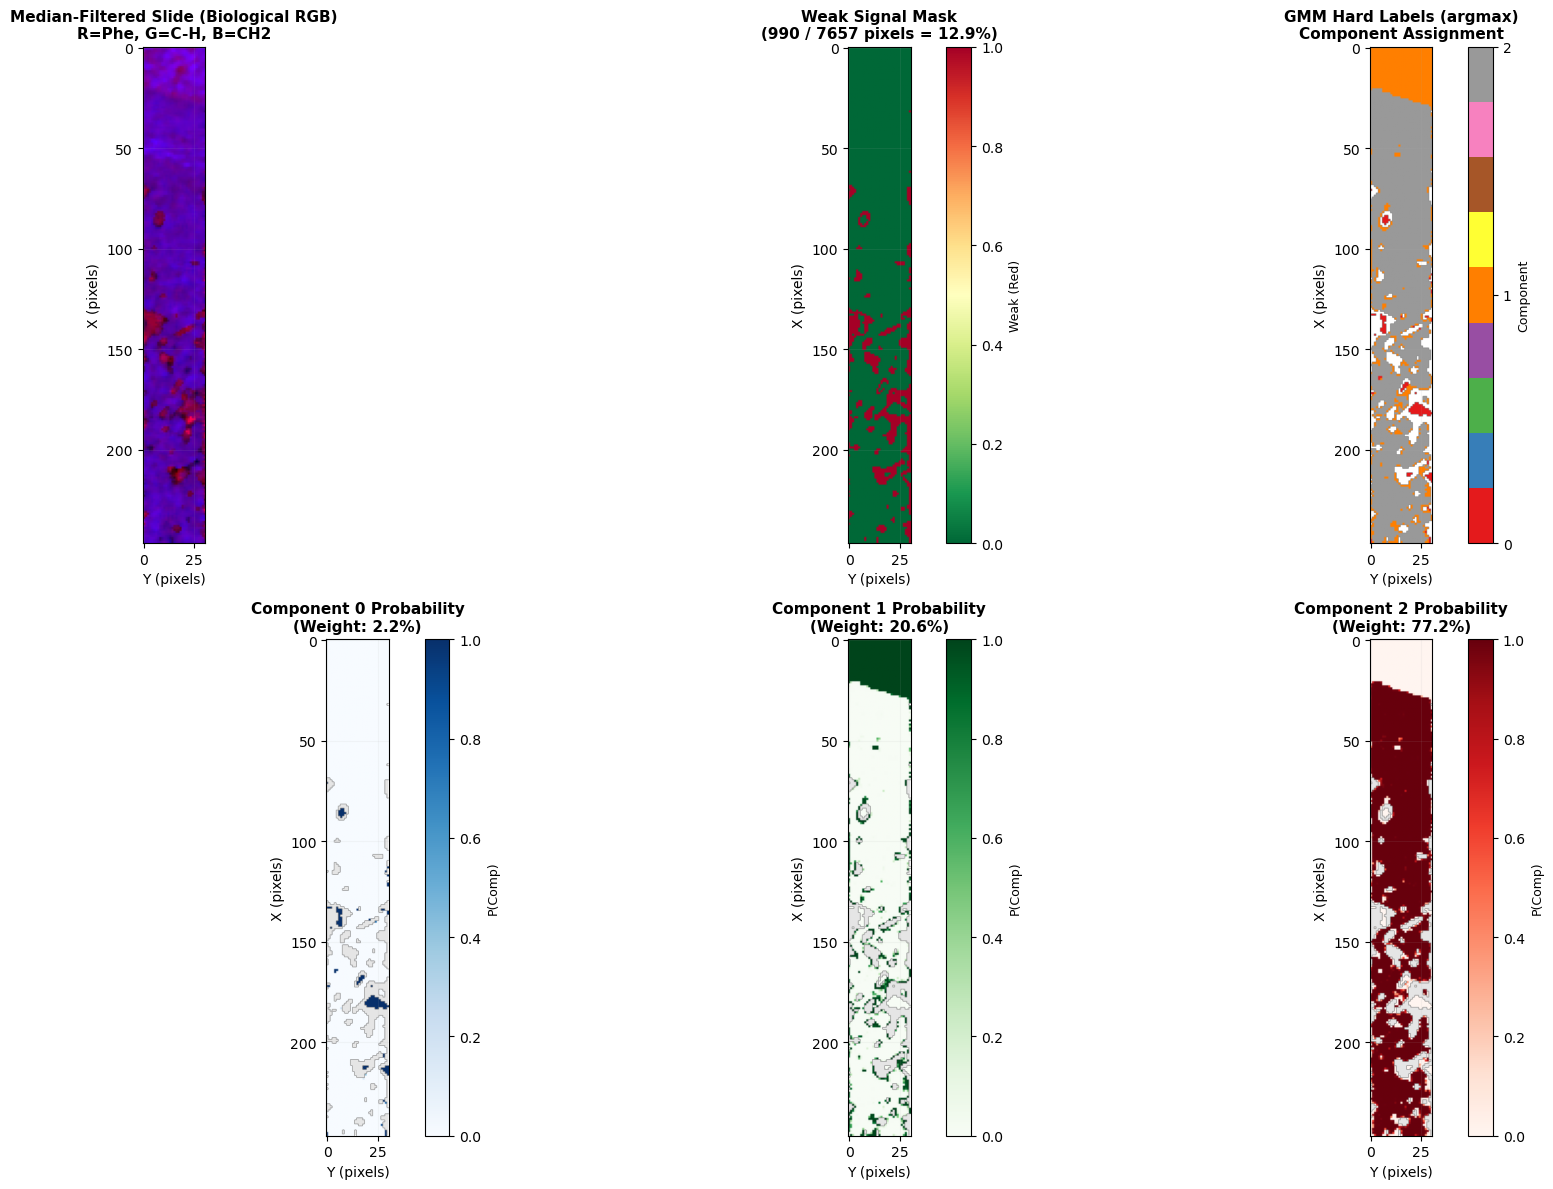


✓ GMM analysis complete!


In [19]:
print("\n" + "="*80)
print("GMM CLUSTERING: Filter Strong Signals & Apply Gaussian Mixture Model")
print("="*80)

from sklearn.mixture import GaussianMixture

# Create mask of STRONG signal spectra (inverse of weak mask)
mask_strong = np.max(data_normalized, axis=1) >= 0.6
n_strong = np.sum(mask_strong)
n_weak = np.sum(mask_weak)

print(f"\nSignal partitioning:")
print(f"  Strong signal spectra (max >= 0.6): {n_strong} ({100*n_strong/(X*Y):.1f}%)")
print(f"  Weak signal spectra (max < 0.6): {n_weak} ({100*n_weak/(X*Y):.1f}%)")

# Filter W_nmf to keep only strong signal spectra
W_strong = W_nmf[mask_strong, :]

print(f"\nFiltered W matrix:")
print(f"  Original shape: {W_nmf.shape}")
print(f"  Filtered shape: {W_strong.shape}")
print(f"  Min abundance: {W_strong.min():.4f}")
print(f"  Max abundance: {W_strong.max():.4f}")

# Fit GMM with 3 components
print(f"\nFitting Gaussian Mixture Model (3 components)...")
gmm = GaussianMixture(n_components=3, random_state=42, n_init=10)
gmm.fit(W_strong)

print(f"✓ GMM fit complete")
print(f"  Log-likelihood: {gmm.score(W_strong):.4f}")
print(f"  BIC: {gmm.bic(W_strong):.2f}")
print(f"  Component weights: {gmm.weights_}")

# Get soft labels (probabilities) for each component
# predict_proba returns (n_samples, 3) array of probabilities for each component
soft_labels = gmm.predict_proba(W_strong)

print(f"\nSoft labels shape: {soft_labels.shape}")
print(f"  Component 0 probability: mean={soft_labels[:, 0].mean():.4f}, std={soft_labels[:, 0].std():.4f}")
print(f"  Component 1 probability: mean={soft_labels[:, 1].mean():.4f}, std={soft_labels[:, 1].std():.4f}")
print(f"  Component 2 probability: mean={soft_labels[:, 2].mean():.4f}, std={soft_labels[:, 2].std():.4f}")

# Create spatial maps for each component
spatial_soft_labels_components = []
component_names = ['Component 0', 'Component 1', 'Component 2']
component_colors = ['Blues', 'Greens', 'Reds']  # Distinct color schemes

for comp_idx in range(3):
    # Initialize with NaN for weak signal pixels
    spatial_soft_labels = np.full(X * Y, np.nan)
    
    # Place soft labels in their original pixel locations
    spatial_soft_labels[mask_strong] = soft_labels[:, comp_idx]
    
    # Reshape to spatial grid (X, Y)
    spatial_soft_labels_image = spatial_soft_labels.reshape(X, Y)
    spatial_soft_labels_components.append(spatial_soft_labels_image)
    
    print(f"\n{component_names[comp_idx]} spatial map:")
    print(f"  Valid pixels: {np.sum(~np.isnan(spatial_soft_labels_image))}")
    print(f"  Range (non-NaN): [{np.nanmin(spatial_soft_labels_image):.4f}, {np.nanmax(spatial_soft_labels_image):.4f}]")

# Create 5-panel visualization: RGB + Mask + 3 Components
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Top-Left: Biological RGB image
ax = axes[0]
ax.imshow(rgb_normalized)
ax.set_title(f'Median-Filtered Slide (Biological RGB)\nR=Phe, G=C-H, B=CH2', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)

# Top-Middle: Weak signal mask
ax = axes[1]
im = ax.imshow(mask_image, cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_title(f'Weak Signal Mask\n({n_weak} / {X*Y} pixels = {100*n_weak/(X*Y):.1f}%)', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Weak (Red)', fontsize=9)

# Top-Right: Combined 3-component label (argmax)
ax = axes[2]
# Compute hard labels (argmax of soft labels)
hard_labels = np.full(X * Y, np.nan)
hard_labels[mask_strong] = np.argmax(soft_labels, axis=1)
hard_labels_image = hard_labels.reshape(X, Y)

im = ax.imshow(hard_labels_image, cmap='Set1', vmin=0, vmax=2)
ax.set_title(f'GMM Hard Labels (argmax)\nComponent Assignment', 
             fontsize=11, fontweight='bold')
ax.set_xlabel('Y (pixels)', fontsize=10)
ax.set_ylabel('X (pixels)', fontsize=10)
ax.grid(True, alpha=0.1)
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.set_label('Component', fontsize=9)

# Bottom row: Three component probability maps
for comp_idx in range(3):
    ax = axes[3 + comp_idx]
    im = ax.imshow(spatial_soft_labels_components[comp_idx], cmap=component_colors[comp_idx], vmin=0, vmax=1)
    ax.set_title(f'{component_names[comp_idx]} Probability\n(Weight: {gmm.weights_[comp_idx]:.1%})', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Y (pixels)', fontsize=10)
    ax.set_ylabel('X (pixels)', fontsize=10)
    ax.grid(True, alpha=0.1)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('P(Comp)', fontsize=9)
    
    # Add mask overlay to show missing pixels
    missing_mask = np.isnan(spatial_soft_labels_components[comp_idx])
    if np.any(missing_mask):
        ax.contourf(np.arange(Y), np.arange(X), missing_mask.astype(float), 
                    levels=[0.5, 1.5], colors=['gray'], alpha=0.2)

plt.tight_layout()
plt.savefig('gmm_soft_labels_3components.png', dpi=100, bbox_inches='tight')
print("\n✓ Saved: gmm_soft_labels_3components.png")
plt.show()

print(f"\n✓ GMM analysis complete!")


In [23]:
def find_wavenumber_index(target_wn, wavenumbers_array):
    """Find the index for a target wavenumber"""
    idx = np.argmin(np.abs(wavenumbers_array - target_wn))
    actual_wn = wavenumbers_array[idx]
    return idx, actual_wn

# Usage
idx, actual = find_wavenumber_index(1003, wavenumbers_actual)
print(f"1003 cm⁻¹ → Index {idx} (actual: {actual:.2f} cm⁻¹)")

1003 cm⁻¹ → Index 494 (actual: 1002.68 cm⁻¹)


In [31]:
from sklearn.mixture import GaussianMixture
import numpy as np

# 1. Fit GMM with 3 components on the NMF Abundance matrix (W)
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm_clusters = gmm.fit_predict(W_nmf)

# 2. Calculate the mean spectrum for each of the 3 clusters
# (Using your pre-airPLS, normalized data)
mean_spectra = {i: np.mean(data_normalized[gmm_clusters == i], axis=0) for i in range(3)}


# 5. Extract your pure tumor mask!
tumor_mask = (gmm_clusters == tumor_cluster_id)
pure_tumor_spectra = data_flat_median[tumor_mask]

{0: np.float32(0.51845825), 1: np.float32(0.47836414), 2: np.float32(0.98530424)}
 Automated Annotation Complete:
   Junk/Margin ID: 1
   Healthy ID: 0
   Tumor ID: 2



GMM COMPONENT MEAN SPECTRA
✓ Loaded wavenumber calibration
  Wavenumber range: [50.0, 3399.8] cm⁻¹
  Number of channels: 1738

Hard label distribution (strong signal pixels):
  Component 0: 145 pixels (2.2%)
  Component 1: 1349 pixels (20.2%)
  Component 2: 5173 pixels (77.6%)

Computing mean spectra from median-filtered data...

Component 0:
  Pixels: 145
  Spectrum range: [0.2, 0.7]
  Mean intensity: 0.3

Component 1:
  Pixels: 1349
  Spectrum range: [0.2, 1.0]
  Mean intensity: 0.3

Component 2:
  Pixels: 5173
  Spectrum range: [0.2, 1.0]
  Mean intensity: 0.3
{0: np.float32(0.65540814), 1: np.float32(0.95509833), 2: np.float32(0.98820704)}
 Automated Annotation Complete:
   Junk/Margin ID: 0
   Healthy ID: 2
   Tumor ID: 1

Tissue Type Identification:
  Junk/Margin: Component 0
  Healthy: Component 2
  Tumor: Component 1

✓ Saved: gmm_component_mean_spectra.png


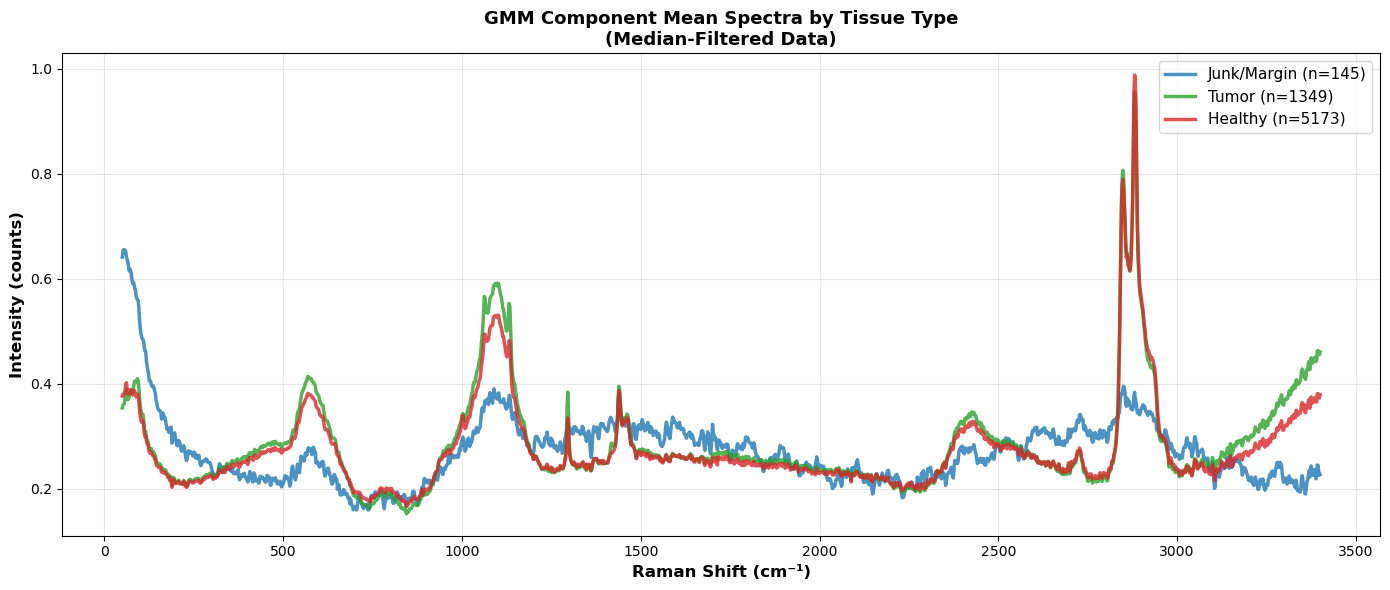


✓ Component mean spectra complete!


In [34]:
print("\n" + "="*80)
print("GMM COMPONENT MEAN SPECTRA")
print("="*80)

# Load actual wavenumbers (Raman shift values) from calibration file
calib_path = Path("../data/RamanFreqTable.csv")
if calib_path.exists():
    calib_df_freq = pd.read_csv(calib_path)
    wavenumbers_actual = calib_df_freq['freq'].values  # Get the freq column with actual cm^-1 values
    print(f"✓ Loaded wavenumber calibration")
    print(f"  Wavenumber range: [{wavenumbers_actual.min():.1f}, {wavenumbers_actual.max():.1f}] cm⁻¹")
    print(f"  Number of channels: {len(wavenumbers_actual)}")
else:
    print(f"⚠ Calibration file not found, using spectral indices")
    wavenumbers_actual = np.arange(Lambda)

# Get hard labels (component assignment) for strong signal pixels
hard_labels_strong = np.argmax(soft_labels, axis=1)

print(f"\nHard label distribution (strong signal pixels):")
n_pixels_per_component = [np.sum(hard_labels_strong == i) for i in range(3)]
for i in range(3):
    print(f"  Component {i}: {n_pixels_per_component[i]} pixels ({100*n_pixels_per_component[i]/len(hard_labels_strong):.1f}%)")

# Compute mean spectrum for each component from raw data
component_mean_spectra = []
component_colors_plot = ['#1f77b4', '#2ca02c', '#d62728']  # Blue, Green, Red
component_labels = ['Component 0', 'Component 1', 'Component 2']

print(f"\nComputing mean spectra from median-filtered data...")
for comp_idx in range(3):
    # Get pixels assigned to this component
    mask_comp = hard_labels_strong == comp_idx
    
    # Get spectra for this component from the strong signal pixels
    spectra_comp = data_normalized[mask_strong, :][mask_comp, :]
    
    # Compute mean spectrum
    mean_spectrum = np.mean(spectra_comp, axis=0)
    component_mean_spectra.append(mean_spectrum)
    
    print(f"\n{component_labels[comp_idx]}:")
    print(f"  Pixels: {n_pixels_per_component[comp_idx]}")
    print(f"  Spectrum range: [{mean_spectrum.min():.1f}, {mean_spectrum.max():.1f}]")
    print(f"  Mean intensity: {mean_spectrum.mean():.1f}")

# IDENTIFY JUNK (Lowest overall signal area)
cluster_areas = {i: np.sum(component_mean_spectra[i]) for i in range(3)}
max_values = {i: np.max(component_mean_spectra[i]) for i in range(3)}
junk_cluster_id = min(max_values, key=max_values.get)
print(max_values)
# IDENTIFY TUMOR (Highest 1003 cm^-1 peak among the remaining two)
remaining_clusters = [i for i in range(3) if i != junk_cluster_id]

phen_index1 = find_wavenumber_index(1031, wavenumbers_actual)[0]  # Get index for 1031 cm^-1
phen_index2 = find_wavenumber_index(1208, wavenumbers_actual)[0]  # Get index for 1208 cm^-1
tumor_cluster_id = max(remaining_clusters, key=lambda i: component_mean_spectra[i][phen_index1]+component_mean_spectra[i][phen_index2])

healthy_cluster_id = [i for i in remaining_clusters if i != tumor_cluster_id][0]

print(f" Automated Annotation Complete:")
print(f"   Junk/Margin ID: {junk_cluster_id}")
print(f"   Healthy ID: {healthy_cluster_id}")
print(f"   Tumor ID: {tumor_cluster_id}")

# Create tissue type labels based on cluster identification
tissue_labels = {}
tissue_labels[junk_cluster_id] = f"Junk/Margin (n={n_pixels_per_component[junk_cluster_id]})"
tissue_labels[healthy_cluster_id] = f"Healthy (n={n_pixels_per_component[healthy_cluster_id]})"
tissue_labels[tumor_cluster_id] = f"Tumor (n={n_pixels_per_component[tumor_cluster_id]})"

print(f"\nTissue Type Identification:")
print(f"  Junk/Margin: Component {junk_cluster_id}")
print(f"  Healthy: Component {healthy_cluster_id}")
print(f"  Tumor: Component {tumor_cluster_id}")

# Plot all 3 mean spectra on the same figure with actual Raman shift on X axis
fig, ax = plt.subplots(figsize=(14, 6))

for i in range(3):
    tissue_type = tissue_labels[i]
    ax.plot(wavenumbers_actual, component_mean_spectra[i], 
            color=component_colors_plot[i], linewidth=2.5, 
            label=tissue_type, alpha=0.8)

ax.set_xlabel('Raman Shift (cm⁻¹)', fontsize=12, fontweight='bold')
ax.set_ylabel('Intensity (counts)', fontsize=12, fontweight='bold')
ax.set_title('GMM Component Mean Spectra by Tissue Type\n(Median-Filtered Data)', 
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gmm_component_mean_spectra.png', dpi=100, bbox_inches='tight')
print("\n✓ Saved: gmm_component_mean_spectra.png")
plt.show()

print(f"\n✓ Component mean spectra complete!")